# Bin packing

A chemical distributor ships 38 drums today in identical vans. A van has a load limit, drums of
the same hazard class may not ride together, and a few specific drums must be kept apart because
their contents react. Every extra van costs a driver and a day. The question is **which drum goes
in which van, so that as few vans as possible leave the yard**.

In this notebook you will:

1. describe the drums and the vans as Python objects,
2. solve the load and draw every van with its drums against the load limit,
3. check the result yourself, without trusting the solver's score,
4. switch a rule off and see what it was costing,
5. change the van size and find out why bigger vans stop helping,
6. restart the search from an existing plan, and add rush drums to a plan already made.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
import itertools
import math
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

from optimaru import bin_packing as bp
from optimaru.bin_packing import constraints as rules
from optimaru.bin_packing.models import BinPackingProblemModel, ItemModel

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the load

Two objects describe the problem, and `bin` on each item is what the solver fills in.

| Object | What it holds |
| --- | --- |
| `Item` | one drum: `id`, `weight`, an optional `color`, and `bin`, the van it ends up in |
| `BinPackingProblem` | `bin_capacity`, the `items`, and `conflicts`, the pairs of ids that must be apart |

All bins are identical. A `color` means "at most one item of this color per bin", which is the
hazard class rule here, and an item with no color is exempt. Weights must be positive integers.

Here is a fictional day: 38 drums, of which 27 carry a hazard class, and 10 pairs that must not
share a van.

In [2]:
HAZARD_CLASSES = ["Flammable"] * 13 + ["Corrosive"] * 8 + ["Oxidizer"] * 6 + [None] * 11


def make_problem(capacity=100):
    """A fresh, unsolved load. Solvers work in place, so each experiment gets its own."""
    rng = np.random.default_rng(5)
    classes = list(HAZARD_CLASSES)
    rng.shuffle(classes)
    items = [
        bp.Item(f"D{i:02d}", int(rng.integers(12, 46)), color=None if hazard is None else str(hazard))
        for i, hazard in enumerate(classes)
    ]
    conflicts = []
    while len(conflicts) < 10:
        first, second = rng.choice(len(items), 2, replace=False)
        conflicts.append((items[first].id, items[second].id))
    return bp.BinPackingProblem(capacity, items, conflicts=conflicts)


problem = make_problem()
print(f"{len(problem.items)} drums, total weight {sum(item.weight for item in problem.items)}, "
      f"van capacity {problem.bin_capacity}")
print("hazard classes:", dict(Counter(item.color for item in problem.items if item.color)))
print("kept apart:", problem.conflicts[:3], "...")

38 drums, total weight 1028, van capacity 100
hazard classes: {'Flammable': 13, 'Corrosive': 8, 'Oxidizer': 6}
kept apart: [('D10', 'D19'), ('D29', 'D08'), ('D11', 'D35')] ...


Two simple counts bound the answer from below before any search runs. The total weight divided by
the capacity, rounded up, is the fewest vans that could carry the weight. The size of the largest
hazard class is the fewest vans that keep that class apart. No plan can beat the larger of the two.

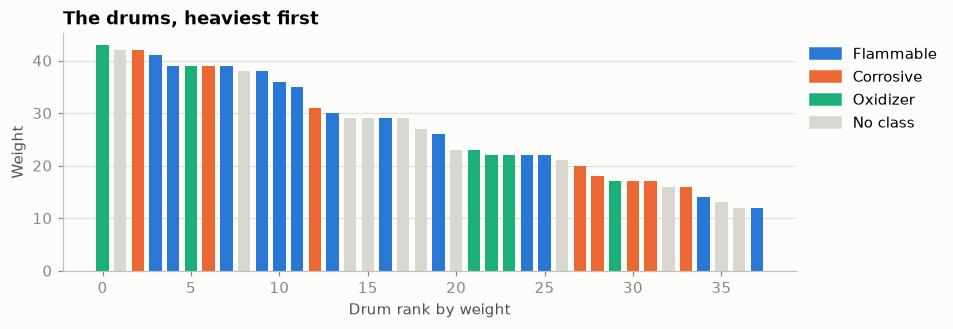

at least 11 vans for the weight, at least 13 for the largest hazard class


In [3]:
def lower_bounds(problem):
    """(vans the weight needs, vans the largest hazard class needs)."""
    weight = sum(item.weight for item in problem.items)
    largest_class = max(Counter(item.color for item in problem.items if item.color).values())
    return math.ceil(weight / problem.bin_capacity), largest_class


CLASS_COLOR = {"Flammable": COLORS[0], "Corrosive": COLORS[1], "Oxidizer": COLORS[2], None: "#d9d8d0"}
CLASS_TEXT = {"Flammable": "white", "Corrosive": "#0b0b0b", "Oxidizer": "#0b0b0b", None: "#0b0b0b"}
legend_handles = [Patch(color=color, label=name or "No class") for name, color in CLASS_COLOR.items()]
outline_handle = Patch(facecolor="#fcfcfb", edgecolor="#0b0b0b", label="Has a conflict partner")

by_weight = sorted(problem.items, key=lambda item: -item.weight)
fig, ax = plt.subplots(figsize=(8.6, 2.8))
ax.bar(range(len(by_weight)), [item.weight for item in by_weight], width=0.7,
       color=[CLASS_COLOR[item.color] for item in by_weight])
ax.set(title="The drums, heaviest first", xlabel="Drum rank by weight", ylabel="Weight")
ax.grid(True, axis="y")
ax.legend(handles=legend_handles, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

by_weight_bound, by_class_bound = lower_bounds(problem)
print(f"at least {by_weight_bound} vans for the weight, at least {by_class_bound} for the largest hazard class")

## 2. Solve it

`bp.solve` fills in `item.bin` on the problem and returns the score. This use case has no compiled
core: it runs a simulated annealing written in Python. The search stops at `time_limit_seconds` or
after `SolverConfig.max_iterations` steps, 50,000 by default, whichever comes first. On a load this
size the step limit usually ends the run first.

The score has two levels, compared in order:

- **hard**: minus the weighted sum of overload, repeated hazard classes and conflict pairs in the
  same van, where `0` means the plan is feasible
- **soft**: minus the number of vans used

In [4]:
score = bp.solve(problem, time_limit_seconds=5, random_seed=42)

print("score   :", score.hard, "/", score.soft)
print("vans    :", problem.bins_used())
best_bound = max(lower_bounds(problem))
if score.hard == 0 and problem.bins_used() == best_bound:
    print(f"this equals the lower bound of {best_bound}, so no feasible plan uses fewer vans")
else:
    print(f"lower bound is {best_bound}, so this is the best found in the time limit, not a proven minimum")

score   : 0 / -13.0
vans    : 13
this equals the lower bound of 13, so no feasible plan uses fewer vans


### Every van, drum by drum

This is the sheet a dispatcher would hand to the loading bay. Each column is a van, each block a
drum, fullest van first. A black outline marks a drum that has a conflict partner somewhere.

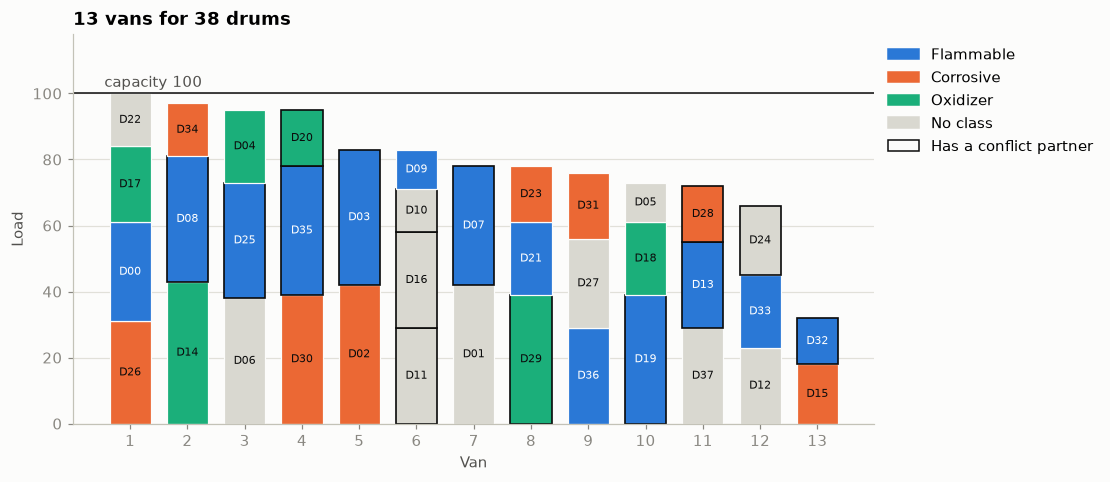

In [5]:
def vans(problem):
    """The items of each used bin, fullest bin first."""
    groups = {}
    for item in problem.items:
        groups.setdefault(item.bin, []).append(item)
    return sorted(groups.values(), key=lambda group: -sum(item.weight for item in group))


def draw_vans(ax, problem, label_drums=True):
    in_conflict = {drum for pair in problem.conflicts for drum in pair}
    for column, group in enumerate(vans(problem)):
        height = 0
        for item in sorted(group, key=lambda item: -item.weight):
            outlined = item.id in in_conflict
            ax.bar(column, item.weight, bottom=height, width=0.72, color=CLASS_COLOR[item.color],
                   edgecolor="#0b0b0b" if outlined else "#fcfcfb", linewidth=1.1 if outlined else 0.8)
            if label_drums:
                ax.text(column, height + item.weight / 2, item.id, ha="center", va="center", fontsize=7.5,
                        color=CLASS_TEXT[item.color])
            height += item.weight
    ax.axhline(problem.bin_capacity, color="#0b0b0b", linewidth=1)
    ax.set_xticks(range(problem.bins_used()), range(1, problem.bins_used() + 1))
    ax.set(ylim=(0, 118), xlabel="Van", ylabel="Load")
    ax.grid(True, axis="y")


fig, ax = plt.subplots(figsize=(9.4, 4.6))
draw_vans(ax, problem)
ax.text(-0.45, problem.bin_capacity + 2, f"capacity {problem.bin_capacity}", color=INK)
ax.set_title(f"{problem.bins_used()} vans for {len(problem.items)} drums")
ax.legend(handles=[*legend_handles, outline_handle], loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 3. Check the result yourself

The answer is one integer per drum, so it can be verified with no solver code. This recomputes
all three hard rules from `item.bin` and the input data.

In [6]:
van_of = {item.id: item.bin for item in problem.items}
loads = Counter()
classes_in_van = Counter()
for item in problem.items:
    loads[item.bin] += item.weight
    if item.color:
        classes_in_van[item.bin, item.color] += 1

print("every drum in a van     :", all(bin_index >= 0 for bin_index in van_of.values()))
print("heaviest van            :", max(loads.values()), "of", problem.bin_capacity)
print("vans over capacity      :", [van for van, load in loads.items() if load > problem.bin_capacity])
print("repeated hazard classes :", [key for key, count in classes_in_van.items() if count > 1])
print("conflict pairs together :", [pair for pair in problem.conflicts if van_of[pair[0]] == van_of[pair[1]]])

every drum in a van     : True
heaviest van            : 100 of 100
vans over capacity      : []
repeated hazard classes : []
conflict pairs together : []


## 4. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and the
`constraints` argument takes the list you want. Only listed constraints are scored. `weight`
scales a rule, `hard` moves it between levels, and `exponent` shapes large violations.

The chart above shows spare room in several vans, and the lower bounds say why: the largest hazard
class sets the van count, not the weight. Suppose a regulator allowed mixed loads. Dropping
`color_compatibility` from the list shows what that rule costs in vans.

bin_capacity
color_compatibility
item_conflicts
minimize_bins


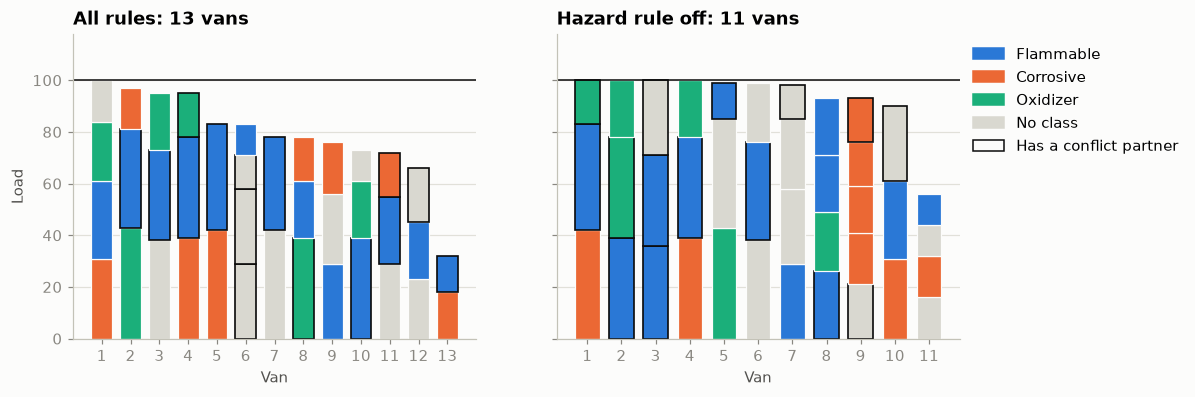

all rules      : score 0 / -13.0
hazard rule off: score 0 / -11.0, 4 van/class pairs now repeat a hazard class


In [7]:
for name in bp.list_constraints():
    print(name)

relaxed = make_problem()
relaxed_score = bp.solve(relaxed, time_limit_seconds=5, random_seed=42, constraints=rules.get_constraints([
    rules.bin_capacity,
    rules.item_conflicts,
    rules.minimize_bins,
]))

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.6), sharey=True, width_ratios=[1, 1])
draw_vans(axes[0], problem, label_drums=False)
draw_vans(axes[1], relaxed, label_drums=False)
axes[0].set_title(f"All rules: {problem.bins_used()} vans")
axes[1].set_title(f"Hazard rule off: {relaxed.bins_used()} vans")
axes[1].set_ylabel("")
axes[1].legend(handles=[*legend_handles, outline_handle], loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

mixed = Counter((item.bin, item.color) for item in relaxed.items if item.color)
print(f"all rules      : score {score.hard} / {score.soft}")
print(f"hazard rule off: score {relaxed_score.hard} / {relaxed_score.soft}, "
      f"{sum(count > 1 for count in mixed.values())} van/class pairs now repeat a hazard class")

## 5. Do bigger vans help?

Buying bigger vans is the obvious way to cut the fleet. Here the same drums are solved for a range
of capacities, next to the two lower bounds from section 1.

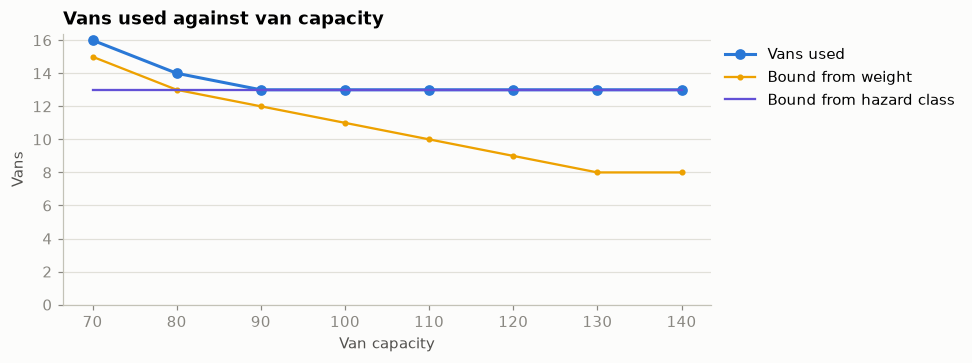

capacity  70: 16 vans, bound 15 set by weight
capacity  80: 14 vans, bound 13 set by hazard class
capacity  90: 13 vans, bound 13 set by hazard class
capacity 100: 13 vans, bound 13 set by hazard class
capacity 110: 13 vans, bound 13 set by hazard class
capacity 120: 13 vans, bound 13 set by hazard class
capacity 130: 13 vans, bound 13 set by hazard class
capacity 140: 13 vans, bound 13 set by hazard class


In [8]:
capacities = list(range(70, 150, 10))
vans_needed, weight_bound, class_bound = [], [], []
for capacity in capacities:
    candidate = make_problem(capacity)
    candidate_score = bp.solve(candidate, time_limit_seconds=5, random_seed=42)
    assert candidate_score.hard == 0, f"no feasible plan found at capacity {capacity}"
    vans_needed.append(candidate.bins_used())
    by_weight_bound, by_class_bound = lower_bounds(candidate)
    weight_bound.append(by_weight_bound)
    class_bound.append(by_class_bound)

fig, ax = plt.subplots(figsize=(7.6, 3.2))
ax.plot(capacities, vans_needed, color=COLORS[0], linewidth=2, marker="o", markersize=6, label="Vans used")
ax.plot(capacities, weight_bound, color=COLORS[3], linewidth=1.5, marker="o", markersize=3,
        label="Bound from weight")
ax.plot(capacities, class_bound, color=COLORS[6], linewidth=1.5, label="Bound from hazard class")
ax.set(title="Vans used against van capacity", xlabel="Van capacity", ylabel="Vans", ylim=(0, None))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for capacity, used, weight, hazard in zip(capacities, vans_needed, weight_bound, class_bound):
    limit = "weight" if weight > hazard else "hazard class"
    print(f"capacity {capacity:3d}: {used:2d} vans, bound {max(weight, hazard):2d} set by {limit}")

Where the line goes flat, the capacity is no longer the limit. The hazard rule needs one van per
drum of the largest class however big the van is, so more capacity buys nothing there. The printed
table names the bound that binds at each size. The way to cut vans past that point is to split the
largest class across two days, not to buy bigger vans.

## 6. Restart from an existing plan

`with_initial_solution` takes a solved `BinPackingProblemModel`, or the same thing as a JSON dict,
and starts the search from its bins. The pydantic models in `optimaru.bin_packing.models` mirror
the problem, and `from_core` and `to_core` convert to and from the objects used above.

**Change `random_seed` between rounds.** A round that finds nothing new leaves the plan as it was,
so with the same seed the next round starts from the same plan with the same random numbers,
repeats the same steps and finds nothing again. The chart runs both ways from the same start, a
construction-only plan from `max_iterations=0` that ignores hazard classes, with a budget of 120
steps per round.

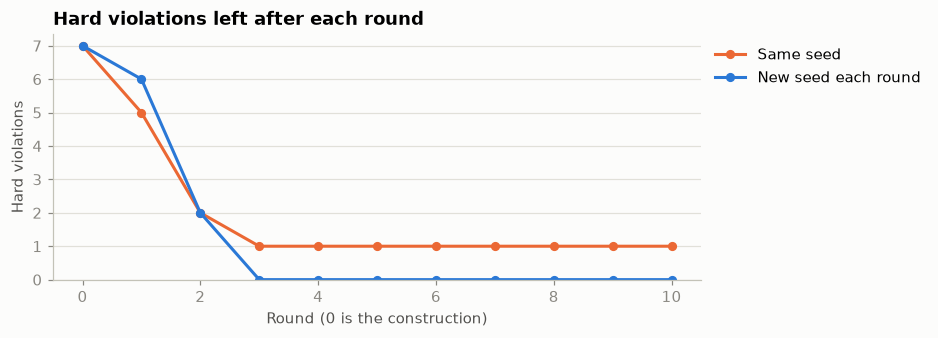

same seed: [7, 5, 2, 1, 1, 1, 1, 1, 1, 1, 1]
new seed : [7, 6, 2, 0, 0, 0, 0, 0, 0, 0, 0]


In [9]:
def run_rounds(seeds, steps=120):
    """Hard violations left after each short round, every round continuing from the previous plan."""
    start = make_problem()
    bp.solve(start, config=bp.SolverConfig(max_iterations=0))
    plan = BinPackingProblemModel.from_core(start)
    history = [-plan.score_hard]
    for seed in seeds:
        warm = bp.with_initial_solution(plan, plan).to_core()
        bp.solve(warm, config=bp.SolverConfig(max_iterations=steps, random_seed=seed))
        plan = BinPackingProblemModel.from_core(warm)
        history.append(-plan.score_hard)
    return history


ROUNDS = 10
same_seed = run_rounds([7] * ROUNDS)
new_seed = run_rounds(range(100, 100 + ROUNDS))

fig, ax = plt.subplots(figsize=(7.6, 2.9))
ax.plot(range(ROUNDS + 1), same_seed, color=COLORS[1], linewidth=2, marker="o", markersize=5, label="Same seed")
ax.plot(range(ROUNDS + 1), new_seed, color=COLORS[0], linewidth=2, marker="o", markersize=5, label="New seed each round")
ax.set(title="Hard violations left after each round", xlabel="Round (0 is the construction)",
       ylabel="Hard violations", ylim=(0, None))
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print("same seed:", same_seed)
print("new seed :", new_seed)

### Rush drums after the plan is made

Four drums arrive after the vans were planned. Items left out of the seed are first-fitted around
the existing vans, then the search repairs what that broke. This use case has no way to pin a drum,
and the score does not reward keeping a plan stable, so drums can move. When the first fit breaks no
rule, the old plan stays until a strictly better one appears, because the search only replaces its
best plan on a strict improvement. To measure the effect, count the pairs of drums that shared a van
in the old plan and still do, which does not depend on how the vans are numbered.

In [10]:
def van_mates(items):
    groups = {}
    for item in items:
        groups.setdefault(item.bin, []).append(item.id)
    return {pair for group in groups.values() for pair in itertools.combinations(sorted(group), 2)}


today = BinPackingProblemModel.from_core(problem)
rush = [("R0", 22, "Corrosive"), ("R1", 17, None), ("R2", 28, "Oxidizer"), ("R3", 19, None)]
updated = today.model_copy(deep=True)
updated.items = [ItemModel(id=item.id, weight=item.weight, color=item.color) for item in today.items]
updated.items += [ItemModel(id=drum, weight=weight, color=hazard) for drum, weight, hazard in rush]

warm = bp.with_initial_solution(updated, today).to_core()
warm_score = bp.solve(warm, time_limit_seconds=5, random_seed=2)
cold = updated.to_core()
cold_score = bp.solve(cold, time_limit_seconds=5, random_seed=2)

before = van_mates(today.items)
print(f"pairs sharing a van in the old plan: {len(before)}")
print(f"from the old plan: score {warm_score.hard} / {warm_score.soft}, "
      f"{len(before & van_mates(warm.items))} pairs kept")
print(f"from scratch     : score {cold_score.hard} / {cold_score.soft}, "
      f"{len(before & van_mates(cold.items))} pairs kept")

pairs sharing a van in the old plan: 39
from the old plan: score 0 / -13.0, 39 pairs kept
from scratch     : score 0 / -13.0, 4 pairs kept


## Next steps

- `use-cases/bin-packing/README.md` covers the solver settings (`temperature`, `cooling_rate`,
  `stagnation_limit`) and how to add your own moves and costs in Python.
- For choosing which items to take at all, rather than how to pack all of them, see `knapsack.ipynb`.